In [ ]:
import os
os.environ['HF_ENDPOINT'] = 'https://hf-mirror.com' 
# set to hf-mirror if you cannot access huggingface.co
os.environ['HF_HOME'] = '/path/to/your/huggingface/cache' # set to your huggingface cache path
os.environ['HF_HUB_OFFLINE'] = '1' # set to '1' to enable offline mode
os.environ["CUDA_VISIBLE_DEVICES"] = '3' # set to your GPU id
import warnings
warnings.filterwarnings("ignore")
import torch
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
from utils import *
import yaml
import itertools
import time

In [2]:
## LeafBench evaluation begins here 

ev_lb= "data/ev_lb.csv"
sv_lb= "data/sv_lb.csv"
file_list = [sv_lb, ev_lb]

with open('benchmark_config.yaml', 'r', encoding='utf-8') as f:
    config = yaml.safe_load(f)

print(type(config))

base_models = {}
test_models = {}

# Prepare all model_path from the leafbench dataset
for i in range(7):
    base_models_i = []
    test_models_i = []

    model_path_1 = config['models'][i]['pretrained_model']['model_path']
    model_path_2 = config['models'][i]['instruct_model']['model_path']
    base_models_i.extend([model_path_1, model_path_2])
    test_models_i.extend([model_path_1, model_path_2])

    for item in config['models'][i]['predeployed_models']:
        model_path_pd_j = item['model_path']
        test_models_i.append(model_path_pd_j)

    base_models[i] = base_models_i
    test_models[i] = test_models_i

# Keep the later cells working with the full per-family test set
model_path = [test_models[i] for i in range(7)]
base_model_paths = [base_models[i] for i in range(7)]
test_model_paths = [test_models[i] for i in range(7)]


<class 'dict'>


In [3]:
import time
start_time=time.perf_counter()
fp_map={}
for i in range(7):
    for item in model_path[i]:
        fp_map[item] = read_fp(item, file_list, k, m).to(device)

time_fp_map=time.perf_counter()
print(f"finish fp_map:{(time_fp_map-start_time):.6f}")

finish fp_map:435.830312


In [4]:
mode = 'l1'

In [5]:
# related model distance for models in the same model family of leafbench
import sys

all_results_related = [['model_family', 'base_model', 'test_model', 'distance']]
for i in range(7):
    family_models = list(dict.fromkeys(base_models[i] + test_models[i]))
    pairs = itertools.combinations(family_models, 2)

        
    with torch.no_grad():
        for item1, item2 in pairs:
            #cnt += 1
            v1 = fp_map[item1]
            v2 = fp_map[item2]
            #l1 disstance
            if mode == 'l1':
                dist = torch.norm(v1-v2, p=1).item()
            elif mode == 'log-scale-l1': 
                dist = torch.norm(torch.log(v1) - torch.log(v2), p=1).item()
            elif mode == 'log-scale-l2':
                dist = torch.norm(torch.log(v1) - torch.log(v2), p=2).item()
            else: 
                print('mode does not exist')
                break
            all_results_related.append([i, item1, item2, dist])


top5 = sorted(all_results_related[1:], key=lambda x: x[3], reverse=True)[:10]
print("Top 10 highest related distances:")
for rank, (family, model1, model2, distance) in enumerate(top5, 1):
    print(f"{rank}. {model1} <-> {model2} | distance={distance:.6f}")

if mode == 'l1':
    filename = 'data/related_lb_l1.csv'
elif mode == 'log-scale-l1': 
    filename = 'data/related_lb_log_l1.csv'
elif mode == 'log-scale-l2':
    filename = 'data/related_lb_log_l2.csv'
else: 
    print('mode does not exist')
    sys.exit()

with open(filename, 'w', newline='', encoding = 'utf-8-sig') as f:
    writer = csv.writer(f)
    writer.writerows(all_results_related)

print('----save all related model distances finished -------------')

Top 10 highest related distances:
1. Edentns/DataVortexTL-1.1B-v0.1 <-> appvoid/dot-v2.7 | distance=73.040550
2. alexredna/TinyLlama-1.1B-Chat-v1.0-reasoning-v2 <-> appvoid/dot-v2.7 | distance=72.937241
3. TinyLlama/TinyLlama-1.1B-Chat-v1.0 <-> appvoid/dot-v2.7 | distance=72.923599
4. appvoid/dot-v2.7 <-> anudaw/distilled-code-llama | distance=72.894852
5. appvoid/dot-v2.7 <-> TheBloke/TinyLlama-1.1B-Chat-v1.0-GPTQ | distance=71.432205
6. appvoid/dot-v2.7 <-> barissglc/tinyllama-tarot-v1 | distance=56.503838
7. Qwen/Qwen2.5-Coder-14B <-> Qwen/Qwen2.5-14B-Instruct-GPTQ-Int4 | distance=25.207474
8. Qwen/Qwen2.5-Math-7B <-> Qwen/Qwen2.5-Coder-7B-Instruct | distance=24.313742
9. Qwen/Qwen2.5-Coder-14B <-> oxyapi/oxy-1-small | distance=23.203686
10. Qwen/Qwen2.5-Coder-14B <-> deepseek-ai/DeepSeek-R1-Distill-Qwen-14B | distance=22.966568
----save all related model distances finished -------------


In [6]:
## Create unrealted model comparision pairs in leafbench

dist_unrelated=[]
all_results_unrelated = [['model1', 'model2', 'distance']]
with torch.no_grad():
    for i, (model1, model2) in enumerate(itertools.combinations(model_path, 2)):
        for item1, item2 in itertools.product(model1, model2):
            v1 = fp_map[item1]
            v2 = fp_map[item2]
            #l1 disstance
            if mode == 'l1':
                dist = torch.norm(v1-v2, p=1).item()
            elif mode == 'log-scale-l1': 
                dist = torch.norm(torch.log(v1) - torch.log(v2), p=1).item()
            elif mode == 'log-scale-l2':
                dist = torch.norm(torch.log(v1) - torch.log(v2), p=2).item()
            else: 
                print('mode does not exist')
                sys.exit()

            

            dist_unrelated.append(dist)
            all_results_unrelated.append([item1, item2, dist])

print('--------------------------------------------------------------------------')
top10_smallest = sorted(all_results_unrelated[1:], key=lambda x: x[2])[:10]
print("10 smallest distances of unrelated models:")
for rank, (m1, m2, d) in enumerate(top10_smallest, 1):
    print(f"{rank}. {m1} <-> {m2} | distance={d:.6f}")

if mode == 'l1':
    filename = 'data/unrelated_lb_l1.csv'
elif mode == 'log-scale-l1': 
    filename = 'data/unrelated_lb_log_l1.csv'
elif mode == 'log-scale-l2':
    filename = 'data/unrelated_lb_log_l2.csv'
else: 
    print('mode does not exist')
    sys.exit()

with open(filename, 'w', newline='', encoding = 'utf-8-sig') as f:
    writer = csv.writer(f)
    writer.writerows(all_results_unrelated)

print('----save all unrelated model distances finished -------------')

--------------------------------------------------------------------------
10 smallest distances of unrelated models:
1. proxectonos/Llama-3.1-Carballo <-> RedHatAI/Mistral-7B-Instruct-v0.3-GPTQ-4bit | distance=24.063568
2. proxectonos/Llama-3.1-Carballo <-> KurmaAI/AQUA-7B | distance=24.445530
3. proxectonos/Llama-3.1-Carballo <-> eganwo/mistral7b-distilled-from-deepseek-r1-qwen32b | distance=24.624287
4. proxectonos/Llama-3.1-Carballo <-> chaymaemerhrioui/mistral-Brain_Model_ACC_Trainer | distance=24.632637
5. proxectonos/Llama-3.1-Carballo <-> mistralai/Mistral-7B-Instruct-v0.3 | distance=24.638004
6. proxectonos/Llama-3.1-Carballo <-> grimjim/Mistral-7B-Instruct-demi-merge-v0.3-7B | distance=24.641024
7. proxectonos/Llama-3.1-Carballo <-> mistralai/Mistral-7B-v0.3 | distance=24.643019
8. proxectonos/Llama-3.1-Carballo <-> openfoodfacts/spellcheck-mistral-7b | distance=24.647511
9. Xiaojian9992024/Llama3.1-8B-ExtraMix <-> RedHatAI/Mistral-7B-Instruct-v0.3-GPTQ-4bit | distance=26.356

In [7]:
threshold = 26

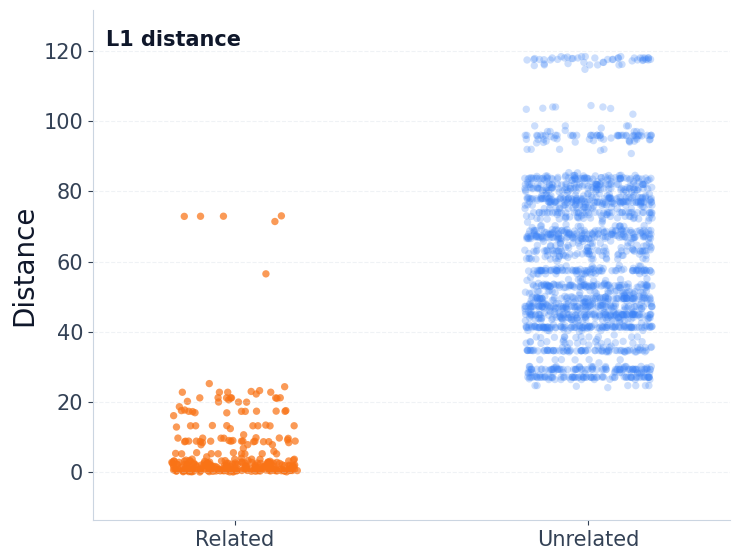

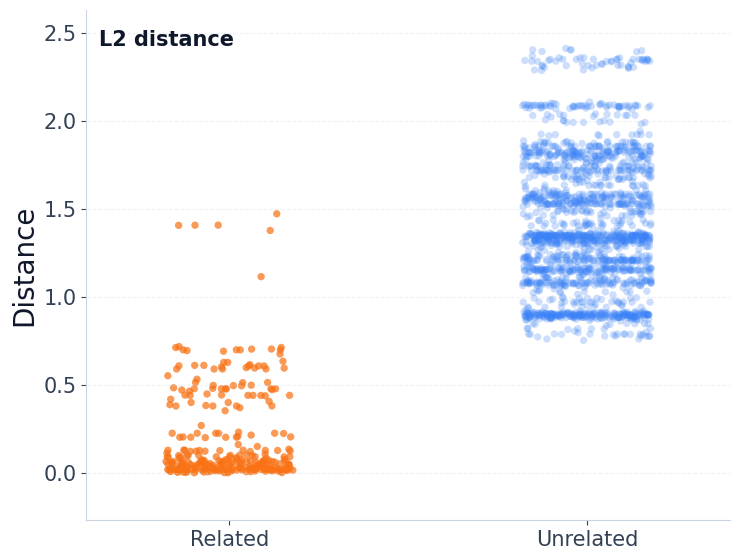

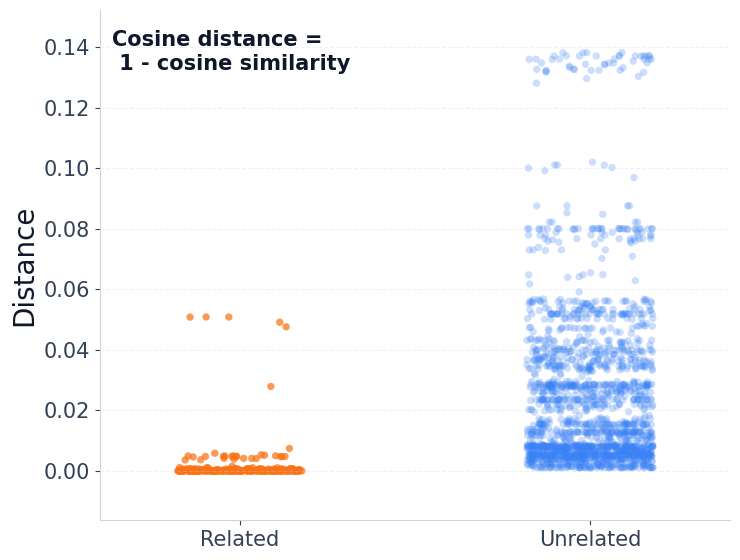

distribution summary:
L1 distance: related_n=289, unrelated_n=1849
L2 distance: related_n=289, unrelated_n=1849
Cosine distance = 
 1 - cosine similarity: related_n=289, unrelated_n=1849


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#cbd5e1',
    'axes.labelcolor': '#0f172a',
    'text.color': '#0f172a',
    'xtick.color': '#334155',
    'ytick.color': '#334155',
    'grid.color': '#cbd5e1',
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
})


def collect_metric_distributions(metric_name):
    related_distances = []
    unrelated_distances = []

    with torch.no_grad():
        for i in range(7):
            family_models = list(dict.fromkeys(base_models[i] + test_models[i]))
            for item1, item2 in itertools.combinations(family_models, 2):
                v1 = fp_map[item1]
                v2 = fp_map[item2]

                if metric_name == 'l1':
                    dist = torch.norm(v1 - v2, p=1).item()
                elif metric_name == 'l2':
                    dist = torch.norm(v1 - v2, p=2).item()
                elif metric_name == 'cosine':
                    cos_sim = F.cosine_similarity(
                        v1.mean(dim=0, keepdim=True),
                        v2.mean(dim=0, keepdim=True),
                    ).item()
                    dist = 1.0 - cos_sim
                else:
                    raise ValueError(f'Unsupported metric: {metric_name}')

                related_distances.append(dist)

        for family_a, family_b in itertools.combinations(range(7), 2):
            for item1 in model_path[family_a]:
                for item2 in model_path[family_b]:
                    v1 = fp_map[item1]
                    v2 = fp_map[item2]

                    if metric_name == 'l1':
                        dist = torch.norm(v1 - v2, p=1).item()
                    elif metric_name == 'l2':
                        dist = torch.norm(v1 - v2, p=2).item()
                    elif metric_name == 'cosine':
                        cos_sim = F.cosine_similarity(
                            v1.mean(dim=0, keepdim=True),
                            v2.mean(dim=0, keepdim=True),
                        ).item()
                        dist = 1.0 - cos_sim
                    else:
                        raise ValueError(f'Unsupported metric: {metric_name}')

                    unrelated_distances.append(dist)

    return np.asarray(related_distances, dtype=float), np.asarray(unrelated_distances, dtype=float)


def plot_metric_figure(metric_name, metric_title, related_color, unrelated_color):
    related_distances, unrelated_distances = collect_metric_distributions(metric_name)
    combined = np.concatenate([related_distances, unrelated_distances])

    if combined.size > 0:
        p1, p99 = np.percentile(combined, [1, 99])
        pad = (p99 - p1) * 0.12 if p99 > p1 else 0.2
        y_min = p1 - pad
        y_max = p99 + pad
    else:
        y_min, y_max = 0.0, 1.0

    rng = np.random.default_rng(42)
    related_x = 0.0 + rng.uniform(-0.18, 0.18, size=len(related_distances))
    unrelated_x = 1.0 + rng.uniform(-0.18, 0.18, size=len(unrelated_distances))

    fig, ax = plt.subplots(figsize=(7.8, 6.0))
    fig.patch.set_facecolor('white')

    ax.scatter(
        related_x,
        related_distances,
        s=28,
        alpha=0.72,
        color=related_color,
        edgecolors='none',
    )
    ax.scatter(
        unrelated_x,
        unrelated_distances,
        s=28,
        alpha=0.26,
        color=unrelated_color,
        edgecolors='none',
    )

    ax.text(0.02, 0.96, metric_title, transform=ax.transAxes, ha='left', va='top', fontsize=15, fontweight='bold')
    ax.set_xlim(-0.4, 1.4)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Related', 'Unrelated'])
    ax.set_ylabel('Distance')
    ax.tick_params(axis='both', labelsize=15)
    ax.grid(True, axis='y', linestyle='--', linewidth=0.8, alpha=0.30)
    ax.grid(False, axis='x')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    fig.tight_layout()

    pdf_name = f'figs/lb_metric_{metric_name}.pdf'
    fig.savefig(pdf_name, format='pdf', dpi=300, facecolor='white', bbox_inches='tight')
    plt.show()

    return related_distances, unrelated_distances


metric_specs = [
    ('l1', 'L1 distance', '#f97316', '#3b82f6'),
    ('l2', 'L2 distance', '#f97316', '#3b82f6'),
    ('cosine', 'Cosine distance = \n 1 - cosine similarity', '#f97316', '#3b82f6'),
]

summaries = []
for metric_name, metric_title, related_color, unrelated_color in metric_specs:
    related_distances, unrelated_distances = plot_metric_figure(
        metric_name,
        metric_title,
        related_color,
        unrelated_color,
    )
    summaries.append((metric_title, related_distances, unrelated_distances))

print('distribution summary:')
for metric_title, related_distances, unrelated_distances in summaries:
    print(f'{metric_title}: related_n={len(related_distances)}, unrelated_n={len(unrelated_distances)}')

AUC = 0.986268
TPR@1%FPR = 0.979239
Best overall accuracy in [22, 33] is at threshold = 24
overall accuracy   : 0.996258


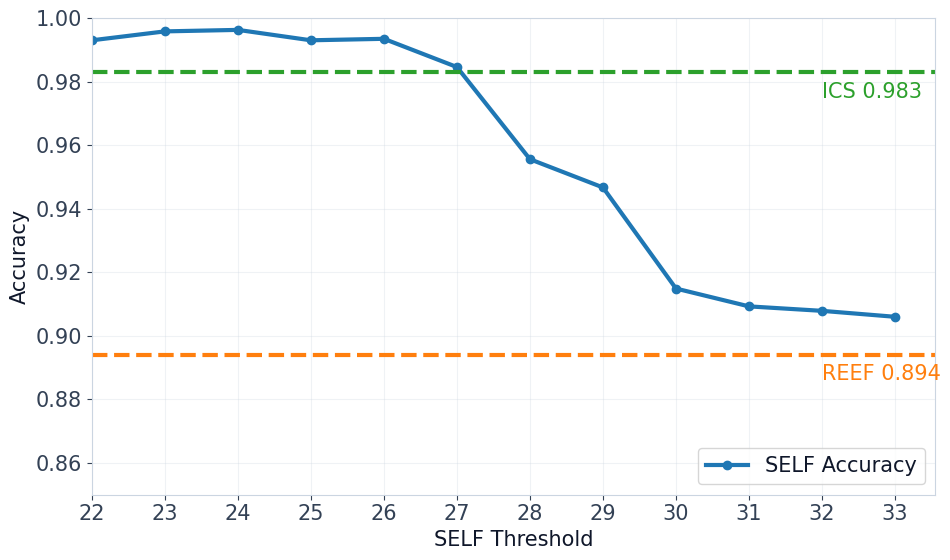

In [9]:
import csv
import numpy as np
import matplotlib.pyplot as plt

related_file = 'data/related_lb_l1.csv'
unrelated_file = 'data/unrelated_lb_l1.csv'


def evaluate_thresholds_and_plot(related_csv, unrelated_csv, threshold_start=22, threshold_end=33, step=1):
    def load_distances(csv_path):
        distances = []
        with open(csv_path, 'r', newline='', encoding='utf-8-sig') as f:
            reader = csv.DictReader(f)
            for row in reader:
                distances.append(float(row['distance']))
        return np.array(distances, dtype=float)

    def compute_auc(related_distances, unrelated_distances):
        positive_count = len(related_distances)
        negative_count = len(unrelated_distances)
        if positive_count == 0 or negative_count == 0:
            return 0.0

        labels = np.concatenate([
            np.ones(positive_count, dtype=int),
            np.zeros(negative_count, dtype=int),
        ])
        scores = -np.concatenate([related_distances, unrelated_distances])

        try:
            from sklearn.metrics import roc_auc_score
            return float(roc_auc_score(labels, scores))
        except Exception:
            order = np.argsort(scores, kind='mergesort')
            sorted_scores = scores[order]
            ranks = np.empty(len(scores), dtype=float)

            i = 0
            while i < len(scores):
                j = i + 1
                while j < len(scores) and sorted_scores[j] == sorted_scores[i]:
                    j += 1
                avg_rank = (i + j - 1) / 2.0 + 1.0
                ranks[order[i:j]] = avg_rank
                i = j

            sum_positive_ranks = ranks[labels == 1].sum()
            auc = (sum_positive_ranks - positive_count * (positive_count + 1) / 2.0) / (positive_count * negative_count)
            return float(auc)

    def compute_tpr_at_fpr(related_distances, unrelated_distances, target_fpr=0.01):
        positive_count = len(related_distances)
        negative_count = len(unrelated_distances)
        if positive_count == 0 or negative_count == 0:
            return 0.0

        labels = np.concatenate([
            np.ones(positive_count, dtype=int),
            np.zeros(negative_count, dtype=int),
        ])
        scores = -np.concatenate([related_distances, unrelated_distances])

        try:
            from sklearn.metrics import roc_curve
            fpr, tpr, _ = roc_curve(labels, scores, pos_label=1)
            valid_indices = np.where(fpr <= target_fpr)[0]
            if len(valid_indices) == 0:
                return 0.0
            return float(tpr[valid_indices[-1]])
        except Exception:
            thresholds = np.unique(scores)[::-1]
            thresholds = np.concatenate([thresholds, [np.inf]])
            best_tpr = 0.0

            for threshold in thresholds:
                predicted_positive = scores >= threshold
                false_positives = np.logical_and(predicted_positive, labels == 0).sum()
                true_positives = np.logical_and(predicted_positive, labels == 1).sum()
                fpr = false_positives / negative_count
                if fpr <= target_fpr:
                    tpr = true_positives / positive_count
                    if tpr > best_tpr:
                        best_tpr = tpr

            return float(best_tpr)

    related_distances = load_distances(related_csv)
    unrelated_distances = load_distances(unrelated_csv)
    auc = compute_auc(related_distances, unrelated_distances)
    tpr_at_1_fpr = compute_tpr_at_fpr(related_distances, unrelated_distances, target_fpr=0.01)

    thresholds = list(range(threshold_start, threshold_end + 1, step))
    overall_accuracies = []

    for threshold in thresholds:
        related_correct = int((related_distances <= threshold).sum())
        unrelated_correct = int((unrelated_distances > threshold).sum())

        related_total = len(related_distances)
        unrelated_total = len(unrelated_distances)
        overall_total = related_total + unrelated_total
        overall_correct = related_correct + unrelated_correct

        overall_accuracy = overall_correct / overall_total if overall_total else 0.0
        overall_accuracies.append(overall_accuracy)

    best_idx = int(np.argmax(overall_accuracies)) if overall_accuracies else 0
    best_threshold = thresholds[best_idx] if thresholds else threshold_start

    print(f"AUC = {auc:.6f}")
    print(f"TPR@1%FPR = {tpr_at_1_fpr:.6f}")
    print(f"Best overall accuracy in [{threshold_start}, {threshold_end}] is at threshold = {best_threshold}")
    print(f"overall accuracy   : {overall_accuracies[best_idx]:.6f}")

    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, overall_accuracies, marker='o', markerfacecolor='tab:blue', markeredgecolor='tab:blue', color='tab:blue', label='SELF Accuracy', linewidth=3)
    plt.axhline(0.983, color='tab:green', linestyle='--', linewidth=3)
    plt.axhline(0.894, color='tab:orange', linestyle='--', linewidth=3)

    ax = plt.gca()
    # Keep the label close to the right edge without leaving a wide blank area after 33.
    x_label_pos = threshold_end - 1
    ax.text(x_label_pos, 0.980, 'ICS 0.983', color='tab:green', va='top', ha='left', fontsize=15)
    ax.text(x_label_pos, 0.891, 'REEF 0.894', color='tab:orange', va='top', ha='left', fontsize=15)

    plt.xlabel('SELF Threshold', fontsize=15)
    plt.ylabel('Accuracy', fontsize=15)
    # plt.title(f'Threshold Sensitivity on LeafBench', fontsize=16)
    plt.xticks(thresholds, fontsize=15)
    plt.yticks(fontsize=15)
    plt.ylim(0.85, 1.0)
    plt.xlim(threshold_start, threshold_end + 0.55)
    plt.grid(True, alpha=0.3)
    plt.legend(loc='lower right', fontsize=15)
    plt.tight_layout()
    plt.gcf().savefig('figs/lb_tau_abs.pdf', format='pdf', dpi=300, bbox_inches='tight')
    plt.show()


    return {
        'thresholds': thresholds,
        'overall_accuracies': overall_accuracies,
        'best_threshold': best_threshold,
        'best_overall_accuracy': overall_accuracies[best_idx] if overall_accuracies else 0.0,
        'auc': auc,
        'tpr_at_1_fpr': tpr_at_1_fpr,
        'ics_reference': 0.983,
        'reef_reference': 0.894,
    }

results = evaluate_thresholds_and_plot(related_file, unrelated_file, threshold_start=22, threshold_end=33, step=1)